# Setup

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from model import HourlySeries
from simulations import StructuralModel, Simulation
from estimation import IVOptions, ModelInputParams, interval
from database import Areas
from synthetic import NonLinearDemand, Consumption, RandomCached, average_supply_price, Supply, get_wind_series, WindOptions, NonLinEquilibrium, IndividualDemand
from synthetic import SUPPLY_INTERCEPT, SUPPLY_SIGMA, SUPPLY_SLOPE

In [2]:
WIND_LAGS: int = 26
AREA = Areas.DE2

ESTIMATORS=[
        ModelInputParams(IVOptions.NL_REGULAR, order=0),
        ModelInputParams(IVOptions.NL_CONDITIONAL_WIND, order=WIND_LAGS),
        ModelInputParams(IVOptions.NL_CONDITIONAL_DEMAND, order=1, order_w=0),
        ModelInputParams(IVOptions.NL_CONDITIONAL_H0, order=WIND_LAGS),
        # ModelInputParams(IVOptions.TRUNCATED_NUISANCE_ORDER, order=50, order_d=1),      # Old model #5
        ModelInputParams(IVOptions.NL_CLEAN_2dim_ORDER, order=WIND_LAGS, order_price=1),          # Old model #6 -> #5
        ModelInputParams(IVOptions.NL_TRUNCATED_IV_2dim_ORDER, order=WIND_LAGS, order_price=1),   # Old model #7 -> #6
        ModelInputParams(IVOptions.NL_IV_2dim_ORDER, order=WIND_LAGS, order_price=1),             # Old model #8 -> #7
        ModelInputParams(IVOptions.NL_NUISANCE_BLOCKED, order_w=WIND_LAGS)                        # New model #8
        # ModelInputParams(IVOptions.IV_2dim_ORDER_BLOCKED, order_w=52, order_price=1),
        ]

In [3]:
YEARS = 5

sample: int = 8760*YEARS
runs: int = 1
model:StructuralModel = StructuralModel.Model_V
wind_manual_ar_sum: float | None = None

INTERVAL = interval(
    start=pd.Timestamp("201901010000"), end=pd.Timestamp("201901010000")+pd.Timedelta(hours=sample)
)

SERIES = HourlySeries(INTERVAL)

# Testing

In [4]:
consumption_analysis_interval: pd.DatetimeIndex = interval(
        start=pd.Timestamp("201901010000"), end=pd.Timestamp("202001282300")
    )

average_demand = Consumption(
            start=consumption_analysis_interval.min(),
            end=consumption_analysis_interval.max(),
            price_area=AREA,
        )().mean()

average_price = average_supply_price(
            quantity=average_demand,
            series=HourlySeries(consumption_analysis_interval),
            price_area=AREA,
        )

In [5]:
SUPPLY = Supply(
    price_area=AREA,
    wind=get_wind_series(
        wind_type=WindOptions.SYNTHETIC_AR_N,
        series=SERIES,
        price_area=AREA,
        synthetic_nlags=WIND_LAGS,
        synthetic_n_observations=sample,
        manual_lags_sum=wind_manual_ar_sum,
    ),
    # error=RandomCached.normal(0, 1),
    # error=RandomCached.normal(0, 500),
    error=RandomCached.normal(0, 1_000),
    slope=SUPPLY_SLOPE,
    intercept=SUPPLY_INTERCEPT-20_000,
)

In [6]:
price = 57
(9000 + price * (-80) + price**2 * (-0.05)) / 0.1

42775.5

In [7]:
DEMAND = NonLinearDemand(
    base_constant=average_demand,
    lags={-1: 0.5},
    b_lin=-100,
    b_sqr=-1,
    error=RandomCached.normal(0, 3_000),
    # error=RandomCached.normal(0, 20),
    average_supply_price=average_price,
    cross_price_elasticity={},
)
LIN_DEMAND = IndividualDemand(
    base_constant=average_demand,
    lags={-1: 0.9},
    elasticity=-100,
    error=RandomCached.normal(0, 4_000),
    average_supply_price=average_price,
    cross_price_elasticity={},
    inventory_beta=0,
)
print(f"Constant term = {DEMAND.constant}, {DEMAND.base_constant}")
print(f"At price = 0, {DEMAND(0, time=consumption_analysis_interval.min(), lagged_price={-1:0}, lagged_demand={-1:DEMAND.base_constant})} MW")
print(f"Fallback = {DEMAND.fallback(None)} MW")

Constant term = 34085.865925644415, 57658.519189991515
At price = 0, 63391.608154921196 MW
Fallback = 50273.73185128883 MW


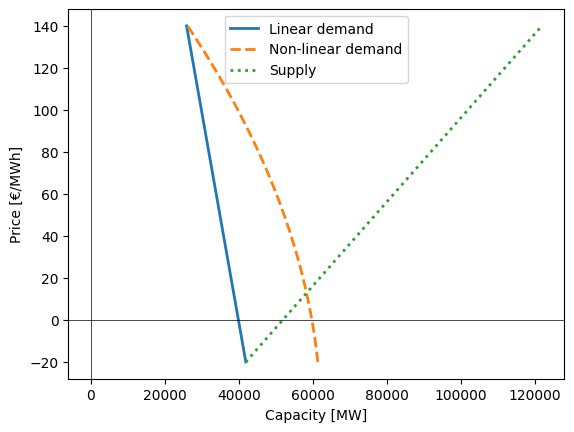

In [8]:
prices = np.linspace(-20, 140, num=1000)
demand = []
for t in range(1000):
    demand.append(DEMAND(
        price=prices[t],
        time=consumption_analysis_interval[0],
        lagged_price={-1:0},
        lagged_demand={-1:DEMAND.fallback(None)},
    ))

supply = [SUPPLY(prices[t], consumption_analysis_interval[0]) for t in range(len(prices))]
lin_demand = [LIN_DEMAND(prices[t], consumption_analysis_interval[0], lagged_price={-1:0}, lagged_demand={-1:LIN_DEMAND.fallback(None)}, past_inventory=0) for t in range(len(prices))]

plt.plot(lin_demand, prices, lw=2, label="Linear demand")
plt.plot(demand, prices, lw=2, label="Non-linear demand", ls="--")
plt.plot(supply, prices, lw=2, label="Supply", ls=":")
plt.axhline(0, ls="-", c="k", lw=0.5)
plt.axvline(0, ls="-", c="k", lw=0.5)
plt.xlabel("Capacity [MW]")
plt.ylabel("Price [€/MWh]")
plt.legend()

## Check range

In [9]:
EQUILIBRIUM = NonLinEquilibrium(
    supply=SUPPLY, 
    demand=DEMAND,
    times=INTERVAL,
    analytical_solution=True
)
EQUILIBRIUM.clearing.demand

print(EQUILIBRIUM.clearing.price.min(), EQUILIBRIUM.clearing.price.max())

9.7654920275981 101.76721510416888


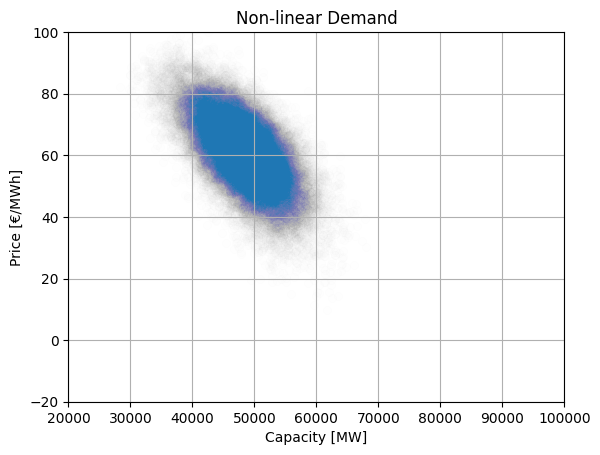

In [10]:
plt.scatter(EQUILIBRIUM.clearing.demand, EQUILIBRIUM.clearing.price, alpha=0.005)
plt.xlabel("Capacity [MW]")
plt.ylabel("Price [€/MWh]")
plt.title("Non-linear Demand")
plt.xlim(20_000, 100_000)
plt.ylim(-20, 100)
plt.grid(True)


In [ ]:
# from synthetic import IndEquilibrium


# LIN_EQUILIBRIUM = IndEquilibrium(
#     supply=SUPPLY, 
#     demand=LIN_DEMAND,
#     times=INTERVAL,
#     analytical_solution=True
# )

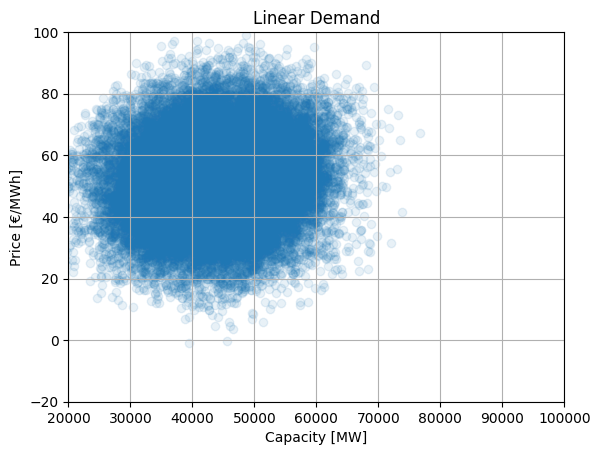

In [ ]:
# plt.scatter(LIN_EQUILIBRIUM.clearing.demand, LIN_EQUILIBRIUM.clearing.price, alpha=0.1)
# plt.xlabel("Capacity [MW]")
# plt.ylabel("Price [€/MWh]")
# plt.title("Linear Demand")
# plt.xlim(20_000, 100_000)
# plt.ylim(-20, 100)
# plt.grid(True)


# Simulations

In [13]:
# # Create the empty lists to store the analysis output
# output_lists:dict[str, dict[str, list]] = {}
# for estimator in ESTIMATORS:
#     output_lists[estimator.name] = {"Mean":[],
#                                     "Upper":[],
#                                     "Lower":[]}



# simulation = Simulation(sample=sample)

# simulation.run_simulations_by_model(
#     runs=runs,
#     estimators=ESTIMATORS,
#     model=StructuralModel.Model_V,
#     demand_arg=0.9,
#     simulation_count=0,
#     wind_manual_ar_sum=wind_manual_ar_sum
# )

In [14]:
# simulation.report_as_text()

In [15]:
# simulation.models["I(W0, W0^2)-E(P0, P0^2)-C(W1:W26)_P0"]

## Plotting

In [16]:
from plot_tools import *
from matplotlib.axes import Axes
from matplotlib.lines import Line2D
import mpl_toolkits.axisartist as axisartist


### Results

In [17]:
def run_model_simulation(sample:int, estimators:list[ModelInputParams], runs:int, model:StructuralModel) -> tuple[list[list[float]], list[list[float]], list[list[float]], list[str]]:
    simulation = Simulation(sample=sample)

    
    simulation.run_simulations_by_model(runs=runs,
                                        estimators=estimators,
                                        model=model,
                                        demand_arg=0.5 if model in [StructuralModel.Model_I, StructuralModel.Model_V] else None,
                                        progress=False)
    
    results_p0:list[list[float]] = []
    results_p1:list[list[float]] = []
    results_psqr:list[list[float]] = []
    names = [est.latex_name for est in estimators]
    prev_model = list(simulation.models.keys())[0].split("_")[0]

    for name, estimator_results in simulation.models.items():
        # print(name, estimator_results.results)

        new_model = name.split("_")[0]
        if new_model != prev_model:
            prev_model = new_model
            for res_list in [results_p1, results_psqr]:
                if len(res_list) < len(results_p0):
                    res_list.append([])
                
        if "_" not in name or name.endswith("_P0"):
            results_p0.append([res.estimate for res in estimator_results.results])
        elif name.endswith("_P1"):
            results_p1.append([res.estimate for res in estimator_results.results])
        elif name.endswith("_P0^2"):
            results_psqr.append([res.estimate for res in estimator_results.results])
        else:
            pass
            # print(name)
    # This is needed just in case the last one also does not have an estimate for all of them!
    for res_list in [results_p1, results_psqr]:
        if len(res_list) < len(results_p0):
            res_list.append([])

    return results_p0, results_p1, results_psqr, names

In [18]:
def application_boxplot(results_p0:list[list[float]],
                        results_p1:list[list[float]], 
                        results_psqr:list[list[float]], 
                        names:list[str], 
                        output_file:str, 
                        xlim, 
                        own_price_elasticity, 
                        cross_price_elasticity,
                        quadratic_elasticity,
                        replace_ellipsis:bool):
        total_width = (WIDE_WIDTH-1) + 4
        fig, axss = plt.subplots(1, 2, sharex=False,  sharey=True, figsize=(total_width, HEIGHT), width_ratios=[(WIDE_WIDTH-1)/total_width, 4/total_width], subplot_kw={'axes_class': axisartist.Axes})
        # fig, ax0 = plt.subplots(1, 1, sharex=False,  sharey=True, figsize=(WIDE_WIDTH, HEIGHT), subplot_kw={'axes_class': axisartist.Axes})
        ax0: Axes = axss[0]
        ax1: Axes = axss[1]

        names = [f"#{i+1}   {n} " for i, n in enumerate(names)]
        if replace_ellipsis:
             names = [func_replace_ellipsis(name) for name in names]
        xx_p0: list[list[float]] = list(reversed([[result for result in method_results] for method_results in results_p0]))
        xx_p1: list[list[float]] = list(reversed([[result for result in method_results] for method_results in results_p1]))
        xx_psqr: list[list[float]] = list(reversed([[result for result in method_results] for method_results in results_psqr]))
       
        ticks: list[str] = list(reversed(names))
   
        bplot1 = ax0.boxplot(xx_p0, vert=False, patch_artist=True)
        bplot2 = ax0.boxplot(xx_p1, vert=False, patch_artist=True, notch=True)
        bplot3 = ax1.boxplot(xx_psqr, vert=False, patch_artist=True, notch=False)
   
        colors = ["darkorange", "dodgerblue", "darkgreen"]
        bbpp = [bplot1, bplot2, bplot3]
        bbpp = [bplot1, bplot3]
   
        for plot, color in zip(bbpp, colors):
            for patch in plot['boxes']:
                patch.set_facecolor(color)
            for median in plot['medians']:
                median.set_color('black')
   
        legend_elements = [
            bplot1["boxes"][0], 
            bplot2["boxes"][0],
            bplot3["boxes"][0],
            Line2D([0], [0], color='darkorange', linestyle="--",),
            Line2D([0], [0], color='dodgerblue', linestyle=":",),
            Line2D([0], [0], color='darkgreen', linestyle="--",),
        ]
        legend_labels = [
            "estimated linear own-price demand response $\\hat{\\beta}^{PL}$ (part of $P_t\\rightarrow D_t$)", 
            "estimated cross-price demand response $\\hat{\\beta}^{P1}$ ($P_{t-1}\\rightarrow D_t$)",
            "estimated quadratic own-price demand response $\\hat{\\beta}^{PS}$ (part of $P_t\\rightarrow D_t$)", 
            "true linear own-price demand response $\\beta^{PL}$",
            "true cross-price demand response $\\beta^{P1}$",
            "true quadratic own-price demand response $\\beta^{PS}$",
        ]
   
        ax0.tick_params(axis='y', which='both', left=False, labelleft=True, reset=True)
   
        ax0.set_yticks(range(1, len(ticks)+1))
        ax0.set_yticklabels(ticks, fontsize="large")
        ax0.yaxis.grid(visible=False)
        ax0.axis["left"].major_ticklabels.set_ha("left")    # type: ignore
        ax0.axis["left"].major_ticks.set_ticksize(0)        # type: ignore
        
        ax0.set_ylim(0.5, len(ticks)+0.5)
        ax0.set_xlim(xlim)
        
        ax0.axvline(x=0, ls='-', color='k', lw=1, alpha=1)
        ax0.axvline(x=own_price_elasticity, ls='--', color='darkorange', lw=2, alpha=1)
        ax0.axvline(x=cross_price_elasticity, ls=':', color='dodgerblue', lw=2, alpha=1)
        ax1.axvline(x=0, ls='-', color='k', lw=1, alpha=1)
        ax1.axvline(x=quadratic_elasticity, ls='--', color='darkgreen', lw=2, alpha=1)
   
        for h in range(0, len(xx_p0)+1):
                ax0.axhline(y=h + 0.5, ls="-", color="grey", xmin=-0.425, xmax=1, clip_on=False)
                ax1.axhline(y=h + 0.5, ls="-", color="grey", xmin=0, xmax=1, clip_on=False)
    
        # Add estimator validity table
        # plot_table(fig)
        
        
        # Remove duplicate y ticks from right subplot
        ax1.axis["left"].set_visible(False)    # type: ignore
        ax1.axvline(ax1.get_xlim()[0], ls="-", color="k", clip_on=False, lw=0.5)

        # Add the legend to the figure,
        fig.legend(handles=legend_elements, labels=legend_labels, loc='upper center', 
                   ncol=2, bbox_to_anchor=(0.5, 0), fancybox=True, frameon=False, fontsize="large")
    
        save_figure(fig, output_file+"_application_figure", VERSION)
   
  

In [19]:
def application_boxplot(results_p0:list[list[float]],
                        _results_p1:list[list[float]],
                        results_psqr:list[list[float]],
                        names:list[str],
                        output_file:str,
                        xlim,
                        own_price_elasticity,
                        cross_price_elasticity,
                        quadratic_elasticity,
                        replace_ellipsis:bool):

        fig, axss = plt.subplots(1, 2, sharex=False,  sharey=True, figsize=(WIDE_WIDTH, HEIGHT), subplot_kw={'axes_class': axisartist.Axes})

        ax0, ax1 = axss


        names = [f"#{i+1}   {n} " for i, n in enumerate(names)]
        if replace_ellipsis:
             names = [func_replace_ellipsis(name) for name in names]
        xx_p0: list[list[float]] = list(reversed([[result for result in method_results] for method_results in results_p0]))
        # xx_p1: list[list[float]] = list(reversed([[result for result in method_results] for method_results in results_p1]))
        xx_psqr: list[list[float]] = list(reversed([[result for result in method_results] for method_results in results_psqr]))

        ticks: list[str] = list(reversed(names))

        bplot1 = ax0.boxplot(xx_p0, vert=False, patch_artist=True)
        bplot2 = ax1.boxplot(xx_psqr, vert=False, patch_artist=True, notch=True)

        colors = ["darkorange", "dodgerblue", "darkgreen"]
        # bbpp = [bplot1, bplot2, bplot3]
        bbpp = [bplot1, bplot2]

        for plot, color in zip(bbpp, colors):
            for patch in plot['boxes']:
                patch.set_facecolor(color)
            for median in plot['medians']:
                median.set_color('black')

        legend_elements = [
            bplot1["boxes"][0],
            bplot2["boxes"][0],
            Line2D([0], [0], color='darkorange', linestyle="--",),
            Line2D([0], [0], color='dodgerblue', linestyle=":",),
        ]
        legend_labels = [
            "estimated linear own-price demand response $\\hat{\\beta}^{PL}$ (part of $P_t\\rightarrow D_t$)",
            "estimated quadratic own-price demand response $\\hat{\\beta}^{PS}$ (part of $P_t\\rightarrow D_t$)",
            "true linear own-price demand response $\\beta^{PL}$",
            "true quadratic own-price demand response $\\beta^{PS}$",
        ]

        ax0.tick_params(axis='y', which='both', left=False, labelleft=True, reset=True)

        ax0.set_yticks(range(1, len(ticks)+1))
        ax0.set_yticklabels(ticks, fontsize="large")
        ax0.yaxis.grid(visible=False)
        ax0.axis["left"].major_ticklabels.set_ha("left")    # type: ignore
        ax0.axis["left"].major_ticks.set_ticksize(0)        # type: ignore

        ax0.set_ylim(0.5, len(ticks)+0.5)
        ax0.set_xlim(xlim)

        ax0.axvline(x=0, ls='-', color='k', lw=1, alpha=1)
        ax0.axvline(x=own_price_elasticity, ls='--', color='darkorange', lw=2, alpha=1)
        ax1.axvline(x=0, ls='-', color='k', lw=1, alpha=1)
        ax1.axvline(x=quadratic_elasticity, ls='--', color='dodgerblue', lw=2, alpha=1)

        for h in range(0, len(xx_p0)+1):
                ax0.axhline(y=h + 0.5, ls="-", color="grey", xmin=-1.8, xmax=1, clip_on=False)
                ax1.axhline(y=h + 0.5, ls="-", color="grey", xmin=0, xmax=1, clip_on=False)

        # Remove duplicate y ticks from right subplot
        ax1.axis["left"].set_visible(False)    # type: ignore
        ax1.set_xlim(-3, 1)
        ax1.axvline(-3, ls="-", color="k", clip_on=False, lw=1)

        # Add estimator validity table
        plot_table(fig, 0.5)

        # Add the legend to the figure,
        fig.legend(handles=legend_elements, labels=legend_labels, loc='upper center',
                   ncol=2, bbox_to_anchor=(0.35, 0.05), fancybox=True, frameon=False, fontsize="large")

        save_figure(fig, output_file+"_application_figure", VERSION)



In [20]:
def plot_application_boxplot(sample:int, runs:int, output_file:str, model:StructuralModel, estimators:list[ModelInputParams]):
    
    results_p0, results_p1, results_psqr, names = run_model_simulation(
        model=model,
        estimators=estimators,
        sample=sample,
        runs=runs
    )
    
    xlims:dict[StructuralModel, tuple[float, float]] = {
        StructuralModel.Model_I:(-400, 100),
        StructuralModel.Model_II:(-200, 100),
        StructuralModel.Model_III:(-200, 100),
        StructuralModel.Model_V:(-300, 50),
    }

    application_boxplot(
        results_p0=results_p0,
        _results_p1=results_p1,
        results_psqr=results_psqr,
        names=names,
        output_file=output_file,
        xlim=xlims[model],
        own_price_elasticity=-100 if model != StructuralModel.Model_V else -100,
        cross_price_elasticity=50 if model == StructuralModel.Model_III else 0,
        quadratic_elasticity=-1.0,
        replace_ellipsis=False
    )

### Running

In [21]:
# plot_application_boxplot(8760*1, 1, "test_run", StructuralModel.Model_V, estimators=ESTIMATORS)

In [22]:
# plot_application_boxplot(8760*2, 5, "model_V_2_years_5_runs", StructuralModel.Model_V, estimators=ESTIMATORS)

In [23]:
# plot_application_boxplot(8760*5, 10, "model_V_5_years_10_runs", StructuralModel.Model_V, estimators=ESTIMATORS)


In [24]:
# plot_application_boxplot(8760*15, 10, "model_V_15_years_10_runs", StructuralModel.Model_V, estimators=ESTIMATORS)

In [25]:
# plot_application_boxplot(8760*2, 100, "model_V_2_years_100_runs", StructuralModel.Model_V, estimators=ESTIMATORS)


In [26]:
# plot_application_boxplot(8760*5, 100, "model_V_5_years_100_runs", StructuralModel.Model_V, estimators=ESTIMATORS)

In [27]:
# plot_application_boxplot(8760*10, 200, "model_V_10_years_200_runs", StructuralModel.Model_V, estimators=ESTIMATORS)

In [28]:
# plot_application_boxplot(8760*20, 200, "model_V_20_years_200_runs", StructuralModel.Model_V, estimators=ESTIMATORS)


In [29]:
# plot_application_boxplot(8760*25, 50, "model_V_25_years_50_runs", StructuralModel.Model_V, estimators=ESTIMATORS)

In [30]:
# plot_application_boxplot(8760*10, 50, "test_run", StructuralModel.Model_V, estimators=ESTIMATORS)

In [31]:
# plot_application_boxplot(8760*5, 20, "model_V_5_years_20_runs", StructuralModel.Model_V, estimators=ESTIMATORS)


# Application

In [32]:
def run_model_application(sample:int, estimators:list[ModelInputParams], runs:int, model:StructuralModel) -> tuple[list[list[float]], list[list[float]], list[list[float]], list[str]]:
    simulation = Simulation(sample=sample)

    
    simulation.run_simulations_by_model(runs=runs,
                                        estimators=estimators,
                                        model=model,
                                        demand_arg=0.5 if model in [StructuralModel.Model_I, StructuralModel.Model_V] else None,
                                        progress=False)
    
    results_p0:list[list[float]] = []
    results_p1:list[list[float]] = []
    results_psqr:list[list[float]] = []
    names = [est.latex_name for est in estimators]
    prev_model = list(simulation.models.keys())[0].split("_")[0]

    for name, estimator_results in simulation.models.items():
        # print(name, estimator_results.results)

        new_model = name.split("_")[0]
        if new_model != prev_model:
            prev_model = new_model
            for res_list in [results_p1, results_psqr]:
                if len(res_list) < len(results_p0):
                    res_list.append([])
                
        if "_" not in name or name.endswith("_P0"):
            results_p0.append([res.estimate for res in estimator_results.results])
        elif name.endswith("_P1"):
            results_p1.append([res.estimate for res in estimator_results.results])
        elif name.endswith("_P0^2"):
            results_psqr.append([res.estimate for res in estimator_results.results])
        else:
            pass
            # print(name)
    # This is needed just in case the last one also does not have an estimate for all of them!
    for res_list in [results_p1, results_psqr]:
        if len(res_list) < len(results_p0):
            res_list.append([])

    return results_p0, results_p1, results_psqr, names

In [33]:
def application_plot(results_p0:list[list[float]],
                        _results_p1:list[list[float]],
                        results_psqr:list[list[float]],
                        names:list[str],
                        output_file:str,
                        xlim,
                        own_price_elasticity,
                        cross_price_elasticity,
                        quadratic_elasticity,
                        replace_ellipsis:bool):

        fig, axss = plt.subplots(1, 2, sharex=False,  sharey=True, figsize=(WIDE_WIDTH, HEIGHT), subplot_kw={'axes_class': axisartist.Axes})

        ax0, ax1 = axss


        names = [f"#{i+1}   {n} " for i, n in enumerate(names)]
        if replace_ellipsis:
             names = [func_replace_ellipsis(name) for name in names]
        xx_p0: list[list[float]] = list(reversed([[result for result in method_results] for method_results in results_p0]))
        # xx_p1: list[list[float]] = list(reversed([[result for result in method_results] for method_results in results_p1]))
        xx_psqr: list[list[float]] = list(reversed([[result for result in method_results] for method_results in results_psqr]))

        ticks: list[str] = list(reversed(names))

        bplot1 = ax0.boxplot(xx_p0, vert=False, patch_artist=True)
        bplot2 = ax1.boxplot(xx_psqr, vert=False, patch_artist=True, notch=True)

        colors = ["darkorange", "dodgerblue", "darkgreen"]
        # bbpp = [bplot1, bplot2, bplot3]
        bbpp = [bplot1, bplot2]

        for plot, color in zip(bbpp, colors):
            for patch in plot['boxes']:
                patch.set_facecolor(color)
            for median in plot['medians']:
                median.set_color('black')

        legend_elements = [
            bplot1["boxes"][0],
            bplot2["boxes"][0],
            Line2D([0], [0], color='darkorange', linestyle="--",),
            Line2D([0], [0], color='dodgerblue', linestyle=":",),
        ]
        legend_labels = [
            "estimated linear own-price demand response $\\hat{\\beta}^{PL}$ (part of $P_t\\rightarrow D_t$)",
            "estimated quadratic own-price demand response $\\hat{\\beta}^{PS}$ (part of $P_t\\rightarrow D_t$)",
            "true linear own-price demand response $\\beta^{PL}$",
            "true quadratic own-price demand response $\\beta^{PS}$",
        ]

        ax0.tick_params(axis='y', which='both', left=False, labelleft=True, reset=True)

        ax0.set_yticks(range(1, len(ticks)+1))
        ax0.set_yticklabels(ticks, fontsize="large")
        ax0.yaxis.grid(visible=False)
        ax0.axis["left"].major_ticklabels.set_ha("left")    # type: ignore
        ax0.axis["left"].major_ticks.set_ticksize(0)        # type: ignore

        ax0.set_ylim(0.5, len(ticks)+0.5)
        ax0.set_xlim(xlim)

        ax0.axvline(x=0, ls='-', color='k', lw=1, alpha=1)
        ax0.axvline(x=own_price_elasticity, ls='--', color='darkorange', lw=2, alpha=1)
        ax1.axvline(x=0, ls='-', color='k', lw=1, alpha=1)
        ax1.axvline(x=quadratic_elasticity, ls='--', color='dodgerblue', lw=2, alpha=1)

        for h in range(0, len(xx_p0)+1):
                ax0.axhline(y=h + 0.5, ls="-", color="grey", xmin=-1.8, xmax=1, clip_on=False)
                ax1.axhline(y=h + 0.5, ls="-", color="grey", xmin=0, xmax=1, clip_on=False)

        # Remove duplicate y ticks from right subplot
        ax1.axis["left"].set_visible(False)    # type: ignore
        ax1.set_xlim(-3, 1)
        ax1.axvline(-3, ls="-", color="k", clip_on=False, lw=1)

        # Add estimator validity table
        plot_table(fig, 0.5)

        # Add the legend to the figure,
        fig.legend(handles=legend_elements, labels=legend_labels, loc='upper center',
                   ncol=2, bbox_to_anchor=(0.35, 0), fancybox=True, frameon=False, fontsize="large")

        save_figure(fig, output_file+"_application_figure", VERSION)



In [34]:
from estimation import ModelResults, IV_results

def application_plot(
    models: list[ModelInputParams],
    results_p0: list[ModelResults],
    results_psqr: list[ModelResults],
    names: list[str],
    output_file: str,
    xlim_p0,
    xlim_psqr,
    own_price_elasticity,
    quadratic_elasticity,
    replace_ellipsis: bool,
):

    demand = COUNTRY.consumption[COUNTRY.consumption.index.isin(interval)]
    endog = COUNTRY.price[COUNTRY.price.index.isin(interval)]
    instrument = COUNTRY.wind_generation[COUNTRY.wind_generation.index.isin(interval)]
    series = HourlySeries(interval)
    dummy = Dummy(interval)
    
    fig, axss = plt.subplots(
        1, 2,
        sharex=False,
        sharey=True,
        figsize=(WIDE_WIDTH, HEIGHT),
        subplot_kw={"axes_class": axisartist.Axes},
    )

    ax0, ax1 = axss

    names = [f"#{i+1}   {n}" for i, n in enumerate(names)]

    if replace_ellipsis:
        names = [func_replace_ellipsis(name) for name in names]

    #
    # Results
    #

    for mod in models:
        print(f"Starting with {mod.strategy}")

        if isinstance(mod.strategy, IVOptions):
            result: ModelResults = IV_results(
                price_area=Areas.DE2,
                demand=demand,
                price=endog,
                wind=instrument,
                dummy=dummy,
                series=series,
                model=mod,
                n_lags=26,
                controls=controls,
                log_log=log_log,
                minimal_controls=minimal_controls,
                split_gas=split_gas,
                subset_months=subset_months,
                start_hour=start_hour,
                end_hour=end_hour,
                drop_holidays=drop_holidays
            )

        else:
            raise Exception("One of the models is not specified correctly")
        
        if isinstance(result, MultipleModelResults):
            for k in result.estimate.keys():
                if k == '_P0':
                    ci = result.ci['_P0']
                    axs0.errorbar(
                        result.estimate['_P0'],
                        y,
                        xerr=ci[1],
                        fmt="o",
                        capsize=5,
                        color="darkorange",
                        label="Own-price elasticity ($P_t\\rightarrow D_t$)" if first_p0 else ""
                    )
                    method_labels[y] = result.latex_name
                    first_p0 = False
                # elif k == '_P1':
                #     ci = result.ci['_P1']
                #     axs0.errorbar(
                #         result.estimate['_P1'],
                #         y,
                #         xerr=ci[1],
                #         fmt="^",
                #         capsize=5,
                #         color="dodgerblue",
                #         label="Cross-price elasticity ($P_{t-1}\\rightarrow D_t$)" if first_p1 else ""
                #     )
                #     first_p1 = False
        else:
            axs0.errorbar(
                result.estimate,
                y,
                xerr=result.ci[1],
                fmt="o",
                capsize=5,
                color="darkorange"
                
            )
            method_labels[y] = result.latex_name

        y -= 1

        if mod.strategy == IVOptions.CONDITIONAL_WIND:
            civ_wind_results = result

        print(f"Estimate = {result.estimate}")

    assert isinstance(civ_wind_results, ModelResults) and not isinstance(civ_wind_results, MultipleModelResults), "A CIV-Wind strategy is required!"


    # Reverse so that model #1 appears at the top.
    results_p0 = list(reversed(results_p0))
    results_psqr = list(reversed(results_psqr))
    names = list(reversed(names))

    y_positions = np.arange(1, len(names) + 1)

    # ------------------------------------------------------------------
    # Linear own-price response
    # ------------------------------------------------------------------

    for y, result in zip(y_positions, results_p0):
        ax0.errorbar(
            result.estimate,
            y,
            xerr=result.ci[1],
            fmt="o",
            capsize=5,
            color="darkorange",
        )

    ax0.axvline(
        x=0,
        ls="-",
        color="k",
        lw=1,
    )

    ax0.axvline(
        x=own_price_elasticity,
        ls="--",
        color="darkorange",
        lw=2,
    )

    ax0.set_xlim(xlim_p0)

    # ------------------------------------------------------------------
    # Quadratic own-price response
    # ------------------------------------------------------------------

    for y, result in zip(y_positions, results_psqr):
        ax1.errorbar(
            result.estimate,
            y,
            xerr=result.ci[1],
            fmt="o",
            capsize=5,
            color="dodgerblue",
        )

    ax1.axvline(
        x=0,
        ls="-",
        color="k",
        lw=1,
    )

    ax1.axvline(
        x=quadratic_elasticity,
        ls="--",
        color="dodgerblue",
        lw=2,
    )

    ax1.set_xlim(xlim_psqr)

    # ------------------------------------------------------------------
    # Shared y-axis
    # ------------------------------------------------------------------

    ax0.set_yticks(y_positions)
    ax0.set_yticklabels(names, fontsize="large")

    ax0.yaxis.grid(visible=False)

    ax0.axis["left"].major_ticklabels.set_ha("left")
    ax0.axis["left"].major_ticks.set_ticksize(0)

    ax0.set_ylim(0.5, len(names) + 0.5)

    # Remove duplicate y-axis from right panel.
    ax1.axis["left"].set_visible(False)

    # ------------------------------------------------------------------
    # Horizontal separators
    # ------------------------------------------------------------------

    for h in range(len(names) + 1):
        ax0.axhline(
            y=h + 0.5,
            ls="-",
            color="grey",
            xmin=-1.8,
            xmax=1,
            clip_on=False,
        )

        ax1.axhline(
            y=h + 0.5,
            ls="-",
            color="grey",
            xmin=0,
            xmax=1,
            clip_on=False,
        )

    # ------------------------------------------------------------------
    # Legend
    # ------------------------------------------------------------------

    legend_elements = [
        Line2D(
            [0], [0],
            marker="o",
            color="darkorange",
            linestyle="None",
            markersize=7,
        ),
        Line2D(
            [0], [0],
            marker="o",
            color="dodgerblue",
            linestyle="None",
            markersize=7,
        ),
        Line2D(
            [0], [0],
            color="darkorange",
            linestyle="--",
        ),
        Line2D(
            [0], [0],
            color="dodgerblue",
            linestyle="--",
        ),
    ]

    legend_labels = [
        "estimated linear own-price demand response "
        r"$\hat{\beta}^{PL}$ (part of $P_t\rightarrow D_t$)",
        "estimated quadratic own-price demand response "
        r"$\hat{\beta}^{PS}$ (part of $P_t\rightarrow D_t$)",
        r"true linear own-price demand response $\beta^{PL}$",
        r"true quadratic own-price demand response $\beta^{PS}$",
    ]

    fig.legend(
        handles=legend_elements,
        labels=legend_labels,
        loc="upper center",
        ncol=2,
        bbox_to_anchor=(0.35, 0),
        fancybox=True,
        frameon=False,
        fontsize="large",
    )

    # Add estimator validity table.
    plot_table(fig, 0.5)

    save_figure(
        fig,
        output_file + "_application_figure",
        VERSION,
    )

# Plot from Felix

In [35]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from linearmodels.iv import IV2SLS
from estimation import get_IV_model, IVModel, IVResults

from model import Dummy

## CIV Wind

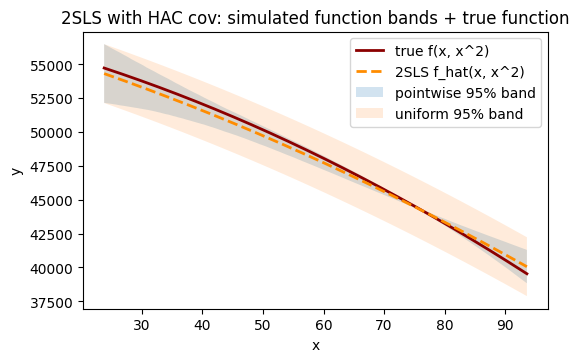

C:\Users\Jorge Sanchez\AppData\Local\Temp\ipykernel_24512\4100056852.py:200: UserWarning: Tight layout not applied. The left and right margins cannot be made large enough to accommodate all Axes decorations.
  plt.tight_layout()


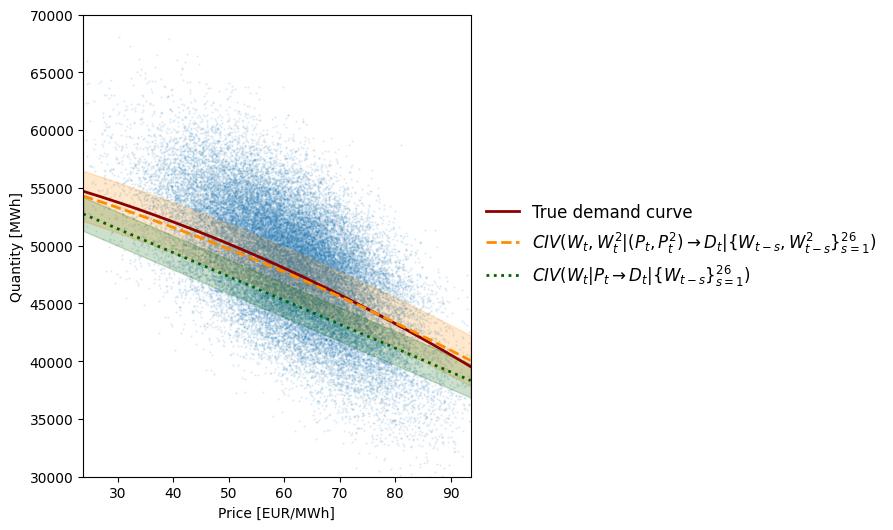

In [58]:
rng = np.random.default_rng(0)

EST_1 = ModelInputParams(IVOptions.NL_CONDITIONAL_WIND, order=26)
EST_2 = ModelInputParams(IVOptions.CONDITIONAL_WIND, order=26)
# EST_3 = ModelInputParams(IVOptions.NL_REGULAR, order=26)

USE_ASF = False

# -----------------------------
# 1) Instrument z_t (persistent)
# -----------------------------
z = EQUILIBRIUM.supply.wind

# -----------------------------------------
# 2) Structural error u_t (serially corr HAC)
# -----------------------------------------
u = None

# -----------------------------------------
# 3) Endogeneity: v correlated with u
# -----------------------------------------
v = None

# ---------------------------------------------------
# 4) First stage: x depends on z and z^2 (strong IV)
# ---------------------------------------------------
x = EQUILIBRIUM.clearing.price

# True structural function
b_true = np.array([EQUILIBRIUM.demand.base_constant, EQUILIBRIUM.demand.b_lin, EQUILIBRIUM.demand.b_sqr]) # (const, x, x^2)
y = EQUILIBRIUM.clearing.demand

df = pd.DataFrame({"y": y, "x": x, "z": z})

# ASF intercept: D_0 + sum_l beta^{Dl} * E[D_{t-l}]
mean_demand = EQUILIBRIUM.clearing.demand.mean()
asf_constant = EQUILIBRIUM.demand.base_constant + sum(
    coef * mean_demand
    for coef in EQUILIBRIUM.demand.lags.values()
)
b_asf = np.array([asf_constant, EQUILIBRIUM.demand.b_lin, EQUILIBRIUM.demand.b_sqr])


# ------------------------------------------------------
# 5) 2SLS: treat x and x^2 as endogenous
# instrument with z, z^2, z^3 (overidentified)
# HAC covariance via kernel (Bartlett)
# ------------------------------------------------------

model_sqr: IVModel = get_IV_model(
    demand=y, price=x, wind=z, 
    series=SERIES, dummy=Dummy(INTERVAL), price_area=AREA,
    model=EST_1,
    controls=False
)
res_sqr: IVResults = model_sqr.fitted_model  # type: ignore

# print(res_sqr.summary)

# ------------------------------------------------------
# 6) Simulated bands from asymptotic N(beta_hat, V_HAC)
# ------------------------------------------------------
cols = ["constant", "price", "price_t^2"]

beta_hat = res_sqr.params[cols].to_numpy()
beta_hat[0] = asf_constant if USE_ASF else EQUILIBRIUM.demand.base_constant
V_hat = res_sqr.cov.loc[cols, cols].to_numpy()

thsh = 0.001
min_x, max_x = df["x"].quantile(thsh), df["x"].quantile(1-thsh)
# min_x, max_x = -10, 120
xgrid = np.linspace(min_x, max_x, num=300)
# xgrid = np.linspace(-10, 120, 500)
Zgrid = np.column_stack([np.ones_like(xgrid), xgrid, xgrid**2])

f_hat = Zgrid @ beta_hat
f_true = Zgrid @ b_asf if USE_ASF else Zgrid @ b_true


B = 5000
beta_draws = rng.multivariate_normal(mean=beta_hat, cov=V_hat, size=B) # (B,3)
f_draws = beta_draws @ Zgrid.T # (B,m) 

# Pointwise 95% band (separate quantiles at each x)
lo_pw = np.quantile(f_draws, 0.025, axis=0)
hi_pw = np.quantile(f_draws, 0.975, axis=0)

# Uniform 95% band (controls max deviation over the whole grid)
dev = np.max(np.abs(f_draws - f_hat), axis=1)
c = np.quantile(dev, 0.95)
lo_u, hi_u = f_hat - c, f_hat + c

# ------------------------------------------------------
# 6) Linear case
# ------------------------------------------------------

model_lin: IVModel = get_IV_model(
    demand=y, price=x, wind=z, 
    series=SERIES, dummy=Dummy(INTERVAL), price_area=AREA,
    model=EST_2,
    controls=False
)
res_lin: IVResults = model_lin.fitted_model  # type: ignore

# print(res_lin.summary)

cols = ["constant", "price"]

beta_hat = res_lin.params[cols].to_numpy()
beta_hat[0] = asf_constant if USE_ASF else EQUILIBRIUM.demand.base_constant #+ EQUILIBRIUM.demand.b_sqr*(EQUILIBRIUM.demand.average_supply_price**2)
# beta_hat = res_lin.params[cols].to_numpy()
V_hat = res_lin.cov.loc[cols, cols].to_numpy()

Zgrid = np.column_stack([np.ones_like(xgrid), xgrid])

f_hat_lin = Zgrid @ beta_hat

B = 5000
beta_draws = rng.multivariate_normal(mean=beta_hat, cov=V_hat, size=B) # (B,3)
f_draws = beta_draws @ Zgrid.T # (B,m) 

# Pointwise 95% band (separate quantiles at each x)
lo_pw_lin = np.quantile(f_draws, 0.025, axis=0)
hi_pw_lin = np.quantile(f_draws, 0.975, axis=0)

# Uniform 95% band (controls max deviation over the whole grid)
dev = np.max(np.abs(f_draws - f_hat_lin), axis=1)
c = np.quantile(dev, 0.95)
lo_u_lin, hi_u_lin = f_hat_lin - c, f_hat_lin + c

# # ------------------------------------------------------
# # 7) ESTIMATOR 3
# # ------------------------------------------------------

# model_3: IVModel = get_IV_model(
#     demand=y, price=x, wind=z, 
#     series=SERIES, dummy=Dummy(INTERVAL), price_area=AREA,
#     model=EST_3,
#     controls=False
# )
# res_naive: IVResults = model_3.fitted_model  # type: ignore

# cols = ["constant", "price", "price_t^2"]

# beta_hat = res_naive.params[cols].to_numpy()
# beta_hat[0] = EQUILIBRIUM.demand.base_constant
# V_hat = res_naive.cov.loc[cols, cols].to_numpy()

# # xgrid = np.linspace(-10, 120, 500)
# Zgrid = np.column_stack([np.ones_like(xgrid), xgrid, xgrid**2])

# f_hat_naive = Zgrid @ beta_hat

# B = 5000
# beta_draws = rng.multivariate_normal(mean=beta_hat, cov=V_hat, size=B) # (B,3)
# f_draws = beta_draws @ Zgrid.T # (B,m) 

# # Pointwise 95% band (separate quantiles at each x)
# lo_pw = np.quantile(f_draws, 0.025, axis=0)
# hi_pw = np.quantile(f_draws, 0.975, axis=0)

# # Uniform 95% band (controls max deviation over the whole grid)
# dev = np.max(np.abs(f_draws - f_hat), axis=1)
# c = np.quantile(dev, 0.95)
# lo_u_naive, hi_u_naive = f_hat - c, f_hat + c


# ------------------------------------------------------
# 8) Plot: data, true curve, estimated curve, bands
# ------------------------------------------------------

plt.figure(figsize=(REGULAR_WIDTH, HEIGHT))
# plt.scatter(df["x"], df["y"], s=10, alpha=0.2, label="data")
plt.plot(xgrid, f_true, linewidth=2, label="true f(x, x^2)", color="darkred")
plt.plot(xgrid, f_hat, linewidth=2, label="2SLS f_hat(x, x^2)", color="darkorange", ls="--")
plt.fill_between(xgrid, lo_pw, hi_pw, alpha=0.2, label="pointwise 95% band")
plt.fill_between(xgrid, lo_u, hi_u, alpha=0.15, label="uniform 95% band")
plt.xlabel("x")
plt.ylabel("y")
plt.legend()
plt.title("2SLS with HAC cov: simulated function bands + true function")
plt.show()

fig = plt.figure(figsize=(5, 6))
# plt.scatter(df["x"], df["y"], s=10, alpha=0.2, label="data")
plt.scatter(x, y, s=0.5, alpha=0.1)
plt.plot(xgrid, f_true, linewidth=2, label="True demand curve" if not USE_ASF else r"$m^*(p)$: average structural function", color="darkred")
plt.plot(xgrid, f_hat, linewidth=2, label=EST_1.latex_name, color="darkorange", ls="--")
plt.plot(xgrid, f_hat_lin, linewidth=2, label=EST_2.latex_name, color="darkgreen", ls=":")
# plt.plot(xgrid, f_hat_naive, linewidth=2, label=EST_3.latex_name, color="dodgerblue", ls="-.")
plt.fill_between(xgrid, lo_u, hi_u, alpha=0.2, label="", color="darkorange")
plt.fill_between(xgrid, lo_u_lin, hi_u_lin, alpha=0.2, label="", color="darkgreen")
# plt.fill_between(xgrid, lo_u_naive, hi_u_naive, alpha=0.15, label="", color="dodgerblue")
plt.xlabel("Price [EUR/MWh]")
plt.ylabel("Quantity [MWh]")
plt.xlim(min_x, max_x)
plt.ylim(30_000, 70_000)
plt.legend(loc='center left', ncol=1, bbox_to_anchor=(1, 0.5), fancybox=True, frameon=False, fontsize="large")
# plt.title("2SLS with HAC cov: simulated function bands + true function")
plt.tight_layout()
plt.show()
save_figure(fig, "non_linear_curve", VERSION, fmt="pdf")
save_figure(fig, "non_linear_curve", VERSION, fmt="svg")
save_figure(fig, "non_linear_curve", VERSION, fmt="jpg")

## NIV

In [37]:
ModelInputParams(IVOptions.NL_CONDITIONAL_DEMAND, order=1, order_w=26).latex_name

'$CIV(\\{W_{{t-s}}, W^2_{{t-s}}\\}_{s=0}^{26}|(P_t, P_t^2)\\rightarrow D_t|D_{t-1})$'

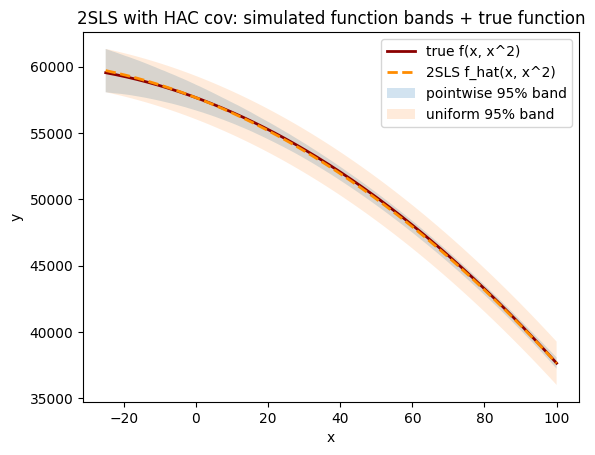

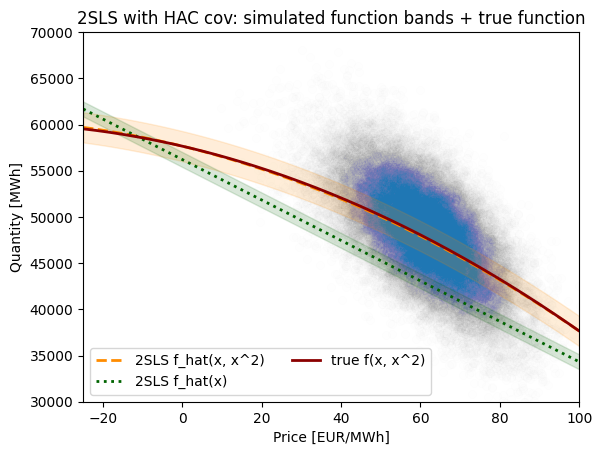

In [38]:
rng = np.random.default_rng(0)
# T = 8760*1

# -----------------------------
# 1) Instrument z_t (persistent)
# -----------------------------
z = EQUILIBRIUM.supply.wind

# -----------------------------------------
# 2) Structural error u_t (serially corr HAC)
# -----------------------------------------
u = None

# -----------------------------------------
# 3) Endogeneity: v correlated with u
# -----------------------------------------
v = None

# ---------------------------------------------------
# 4) First stage: x depends on z and z^2 (strong IV)
# ---------------------------------------------------
x = EQUILIBRIUM.clearing.price

# True structural function
b_true = np.array([EQUILIBRIUM.demand.base_constant, EQUILIBRIUM.demand.b_lin, EQUILIBRIUM.demand.b_sqr]) # (const, x, x^2)
y = EQUILIBRIUM.clearing.demand

df = pd.DataFrame({"y": y, "x": x, "z": z})

# ------------------------------------------------------
# 5) 2SLS: treat x and x^2 as endogenous
# instrument with z, z^2, z^3 (overidentified)
# HAC covariance via kernel (Bartlett)
# ------------------------------------------------------

model_sqr: IVModel = get_IV_model(
    demand=y, price=x, wind=z, 
    series=SERIES, dummy=Dummy(INTERVAL), price_area=AREA,
    model=ModelInputParams(IVOptions.NL_CONDITIONAL_DEMAND, order=1),
    controls=False
)
res_sqr: IVResults = model_sqr.fitted_model  # type: ignore

# print(res_sqr.summary)

# ------------------------------------------------------
# 6) Simulated bands from asymptotic N(beta_hat, V_HAC)
# ------------------------------------------------------
cols = ["constant", "price", "price_t^2"]

beta_hat = res_sqr.params[cols].to_numpy()
beta_hat[0] = EQUILIBRIUM.demand.base_constant
V_hat = res_sqr.cov.loc[cols, cols].to_numpy()

min_x, max_x = df["x"].quantile(0.002), df["x"].quantile(0.998)
min_x, max_x = -25, 100
xgrid = np.linspace(min_x, max_x, 300)
# xgrid = np.linspace(-10, 120, 500)
Zgrid = np.column_stack([np.ones_like(xgrid), xgrid, xgrid**2])

f_hat = Zgrid @ beta_hat
f_true = Zgrid @ b_true

B = 5000
beta_draws = rng.multivariate_normal(mean=beta_hat, cov=V_hat, size=B) # (B,3)
f_draws = beta_draws @ Zgrid.T # (B,m) 

# Pointwise 95% band (separate quantiles at each x)
lo_pw = np.quantile(f_draws, 0.025, axis=0)
hi_pw = np.quantile(f_draws, 0.975, axis=0)

# Uniform 95% band (controls max deviation over the whole grid)
dev = np.max(np.abs(f_draws - f_hat), axis=1)
c = np.quantile(dev, 0.95)
lo_u, hi_u = f_hat - c, f_hat + c

# ------------------------------------------------------
# 6) Linear case
# ------------------------------------------------------

model_lin: IVModel = get_IV_model(
    demand=y, price=x, wind=z, 
    series=SERIES, dummy=Dummy(INTERVAL), price_area=AREA,
    model=ModelInputParams(IVOptions.CONDITIONAL_DEMAND, order=1),
    controls=False
)
res_lin: IVResults = model_lin.fitted_model  # type: ignore

# print(res_lin.summary)

cols = ["constant", "price"]

beta_hat = res_lin.params[cols].to_numpy()
beta_hat[0] = EQUILIBRIUM.demand.base_constant + EQUILIBRIUM.demand.b_sqr*(EQUILIBRIUM.demand.average_supply_price**2)
V_hat = res_lin.cov.loc[cols, cols].to_numpy()

Zgrid = np.column_stack([np.ones_like(xgrid), xgrid])

f_hat_lin = Zgrid @ beta_hat

B = 5000
beta_draws = rng.multivariate_normal(mean=beta_hat, cov=V_hat, size=B) # (B,3)
f_draws = beta_draws @ Zgrid.T # (B,m) 

# Pointwise 95% band (separate quantiles at each x)
lo_pw_lin = np.quantile(f_draws, 0.025, axis=0)
hi_pw_lin = np.quantile(f_draws, 0.975, axis=0)

# Uniform 95% band (controls max deviation over the whole grid)
dev = np.max(np.abs(f_draws - f_hat_lin), axis=1)
c = np.quantile(dev, 0.95)
lo_u_lin, hi_u_lin = f_hat_lin - c, f_hat_lin + c

# ------------------------------------------------------
# 7) Plot: data, true curve, estimated curve, bands
# ------------------------------------------------------
plt.figure()
# plt.scatter(df["x"], df["y"], s=10, alpha=0.2, label="data")
plt.plot(xgrid, f_true, linewidth=2, label="true f(x, x^2)", color="darkred")
plt.plot(xgrid, f_hat, linewidth=2, label="2SLS f_hat(x, x^2)", color="darkorange", ls="--")
plt.fill_between(xgrid, lo_pw, hi_pw, alpha=0.2, label="pointwise 95% band")
plt.fill_between(xgrid, lo_u, hi_u, alpha=0.15, label="uniform 95% band")
plt.xlabel("x")
plt.ylabel("y")
plt.legend()
plt.title("2SLS with HAC cov: simulated function bands + true function")
plt.show()

plt.figure()
# plt.scatter(df["x"], df["y"], s=10, alpha=0.2, label="data")
plt.scatter(x, y, alpha=0.005)
plt.plot(xgrid, f_hat, linewidth=2, label="2SLS f_hat(x, x^2)", color="darkorange", ls="--")
plt.plot(xgrid, f_hat_lin, linewidth=2, label="2SLS f_hat(x)", color="darkgreen", ls=":")
plt.plot(xgrid, f_true, linewidth=2, label="true f(x, x^2)", color="darkred")
plt.fill_between(xgrid, lo_u, hi_u, alpha=0.15, label="", color="darkorange")
plt.fill_between(xgrid, lo_u_lin, hi_u_lin, alpha=0.15, label="", color="darkgreen")
plt.xlabel("Price [EUR/MWh]")
plt.ylabel("Quantity [MWh]")
plt.xlim(min_x, max_x)
plt.ylim(30_000, 70_000)
plt.legend(ncols=2)
plt.title("2SLS with HAC cov: simulated function bands + true function")
plt.show()

# LaTeX names

In [39]:
import matplotlib.pyplot as plt

def visualize_latex(latex:str) -> None:

    fig = plt.figure(figsize=(4, 1))
    plt.text(0.5, 0.5, latex, fontsize=20, ha='center', va='center')
    plt.axis('off')

    plt.savefig("latex.png", dpi=200, bbox_inches='tight', pad_inches=0.1)
    plt.show()

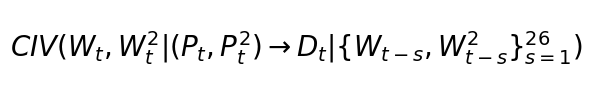

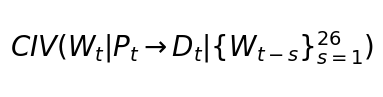

In [40]:
visualize_latex(ModelInputParams(IVOptions.NL_CONDITIONAL_WIND, order=26).latex_name)
visualize_latex(ModelInputParams(IVOptions.CONDITIONAL_WIND, order=26).latex_name)

In [41]:
beta_draws

array([[56148.62596416,  -219.52974392],
       [56209.74628125,  -218.80965051],
       [56059.73502326,  -219.22402683],
       ...,
       [56316.66154775,  -221.4782279 ],
       [55705.80868018,  -216.43284918],
       [56605.83165461,  -222.03599791]], shape=(5000, 2))